# Pre-course refresher: R, probability and simulation

**Bayesian statistics for PhD researchers · Aalborg University · 9–17 November 2026**

This refresher gets everyone to the same starting point before Day 1. It is **self-paced** and **not graded** or submitted. It has seven parts:

| Part | Topic |
|---|---|
| 0 | Install the software and check that Stan works |
| 1 | R essentials with a real dataset |
| 2 | Probability: distributions, expectation, conditioning, Bayes' rule |
| 3 | A little calculus: normalising a density, logs, maximising |
| 4 | Simulation and a first look at a likelihood |
| 5 | Your own research question |
| 6 | Self-check |

**This one notebook is all you need.** Everything (explanations, data, exercises, hints) is here; there are no separate scripts or handouts. Open it in JupyterLab with the **R (bayes)** kernel and run the cells in order. Each task has a code cell to complete and an answer cell for your explanation. Hints are under **Hint**. A worked solution notebook (`pre-course-refresher-solutions.ipynb`) is in the same folder: **try first, then check**.

If a part is easy for you, skim it. If one is hard, note it in the self-check (Part 6) and bring the questions to Day 1. Nothing here is a prerequisite you must master; the course builds everything again from the start.

The data are R's built-in `airquality` dataset: daily air-quality measurements in New York, May–September 1973. They are real data, used here only for practice.

> **Instructor note.** This is the **worked solution** to the pre-course refresher. It may be given to students together with the exercise notebook, since the refresher is self-assessed and not graded.

In [1]:
library(tidyverse)   # dplyr for data, ggplot2 for figures
set.seed(2026)
options(width = 100, repr.plot.width = 8, repr.plot.height = 5)
q90 <- function(x) quantile(x, c(.05, .5, .95))

── Attaching core tidyverse packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

## Part 0 — Software

Follow the course installation guide, `installations.md` (sections 1–3 and 7), or the logistics slides:

1. Install Miniconda.
2. Install the C++ tools: macOS and Linux only.
3. Create the `bayes` environment with R and CmdStan.
4. Add JupyterLab and the **R (bayes)** kernel.

Then run the cell below. It compiles and runs a small Stan model. The first compile can take a minute or two. If it fails, keep the first error message and bring it to Day 1; there is setup help in the first exercise session.

In [2]:
R.version.string
library(cmdstanr)
cmdstan_version()
file <- file.path(cmdstan_path(), "examples", "bernoulli", "bernoulli.stan")
mod <- cmdstan_model(file, quiet = TRUE)
fit <- mod$sample(data = list(N = 10, y = c(0, 1, 0, 0, 0, 0, 0, 0, 0, 1)), seed = 123, refresh = 0, show_messages = FALSE)
fit$summary("theta")

[1] "R version 4.5.3 (2026-03-11)"

This is cmdstanr version 0.9.0

- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr

- CmdStan path: /opt/homebrew/Caskroom/miniconda/base/envs/bayes/bin/cmdstan

- CmdStan version: 2.40.0



[1] "2.40.0"

variable,mean,median,sd,mad,q5,q95,rhat,ess_bulk,ess_tail
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
theta,0.2568822,0.2410806,0.1242848,0.1271501,0.08003641,0.4852967,1.000955,1231.553,1476.736


**Model answer.** A one-row summary for `theta` with a mean near 0.25 means R, CmdStan and the compiler all work. If `library(cmdstanr)` fails, the notebook is probably not using the **R (bayes)** kernel, or JupyterLab was started without `conda activate bayes`.

## Part 1 — R essentials

### R1. Vectors and missing values (20 min)

(a) Create `x <- c(4, 8, NA, 15, 16, 23, 42)`. Compute its length, the number of observed values, the mean ignoring the missing value, and the mean of the values above 10. (b) Explain in one sentence why `mean(x)` returns `NA`, and why removing missing values is a decision, not a technicality.

In [3]:
x <- c(4, 8, NA, 15, 16, 23, 42)
c(length = length(x), observed = sum(!is.na(x)), mean_obs = mean(x, na.rm = TRUE),
  mean_above_10 = mean(x[x > 10 & !is.na(x)]))
mean(x)

length      observed      mean_obs mean_above_10 
            7             6            18            24

[1] NA

**Model answer.** (a) 7 elements, 6 observed, mean 18 (ignoring the NA), mean of values above 10 = 24. (b) R refuses to guess a missing value, so any arithmetic involving it is unknown. Dropping NAs assumes the missing values are not systematically different from the observed ones; if, for example, ozone was missing on stormy days, dropping them biases a summary.

### R2. A data frame (40 min)

`airquality` has columns `Ozone` (ppb), `Solar.R` (langley), `Wind` (mph), `Temp` (°F), `Month` (5–9) and `Day`.

(a) Report the number of rows, the number of missing values in each column, and what one row represents. (b) Create `TempC`, the temperature in °C. (c) Compute the mean, median and SD of `Ozone` for each month, together with the number of observed values. (d) Which month has the highest median ozone, and how many observations is that based on?

In [4]:
aq <- airquality
str(aq)
c(rows = nrow(aq)); colSums(is.na(aq))
aq <- aq |> mutate(TempC = (Temp - 32) * 5 / 9)
aq |>
  filter(!is.na(Ozone)) |>
  group_by(Month) |>
  summarise(n = n(), mean = mean(Ozone), median = median(Ozone), sd = sd(Ozone)) |>
  arrange(desc(median))

'data.frame':	153 obs. of  6 variables:
 $ Ozone  : int  41 36 12 18 NA 28 23 19 8 NA ...
 $ Solar.R: int  190 118 149 313 NA NA 299 99 19 194 ...
 $ Wind   : num  7.4 8 12.6 11.5 14.3 14.9 8.6 13.8 20.1 8.6 ...
 $ Temp   : int  67 72 74 62 56 66 65 59 61 69 ...
 $ Month  : int  5 5 5 5 5 5 5 5 5 5 ...
 $ Day    : int  1 2 3 4 5 6 7 8 9 10 ...


rows 
 153

Ozone Solar.R    Wind    Temp   Month     Day 
     37       7       0       0       0       0

Month,n,mean,median,sd
<int>,<int>,<dbl>,<dbl>,<dbl>
7,26,59.11538,60,31.63584
8,26,59.96154,52,39.68121
6,9,29.44444,23,18.20790
9,29,31.44828,23,24.14182
5,26,23.61538,18,22.22445


**Model answer.** (a) 153 rows; one row is **one day** at one location. Ozone has 37 missing values and Solar.R 7; the others are complete. (c–d) Median ozone is highest in July and August (about 60 and 52 ppb), based on 26 observed days each, and lowest in May and June. The `n` column shows that June has only 9 observed ozone values out of 30 days, so its summaries are much less reliable than the others.

### R3. Write a function (30 min)

Write a function `describe(v)` that returns the number of observed values, the mean, the SD and the **standard error** of the mean (SD/√n) of a numeric vector, ignoring missing values. Apply it to `Ozone`, `Wind` and `TempC`. Why does the standard error get smaller with more data while the SD does not?

In [5]:
describe <- function(v) {
  v <- v[!is.na(v)]; n <- length(v)
  c(n = n, mean = mean(v), sd = sd(v), se = sd(v) / sqrt(n))
}
round(sapply(aq[c("Ozone", "Wind", "TempC")], describe), 2)

,Ozone,Wind,TempC
n,116.00,153.00,153.00
mean,42.13,9.96,25.49
sd,32.99,3.52,5.26
se,3.06,0.28,0.43


**Model answer.** The SD describes how much **individual days** vary; it does not shrink with more data. The standard error describes how precisely the **mean** is estimated from n roughly independent observations, and shrinks like 1/√n. (Consecutive days are not really independent, so the SE here is optimistic, which is a recurring theme in the course.)

### R4. Plots that answer a question (40 min)

Make three labelled plots, with units: (a) a histogram of ozone; (b) boxplots of ozone by month; (c) ozone against temperature (°C) with points coloured by month. In two or three sentences: what does each plot show that the others do not? Is ozone's distribution symmetric?

Warning message:
“Removed 37 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 37 rows containing non-finite outside the scale range (`stat_boxplot()`).”


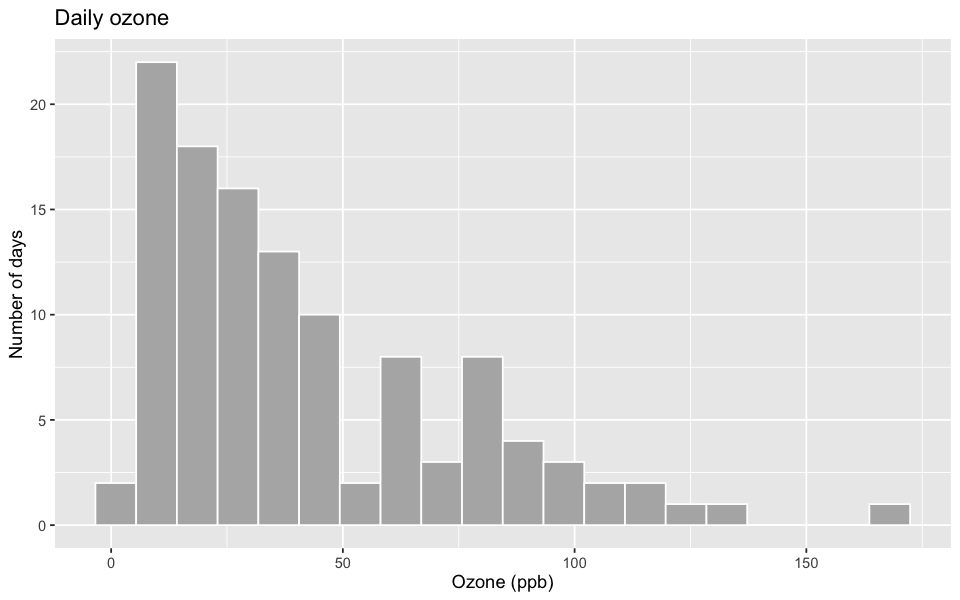

Warning message:
“Removed 37 rows containing missing values or values outside the scale range (`geom_point()`).”


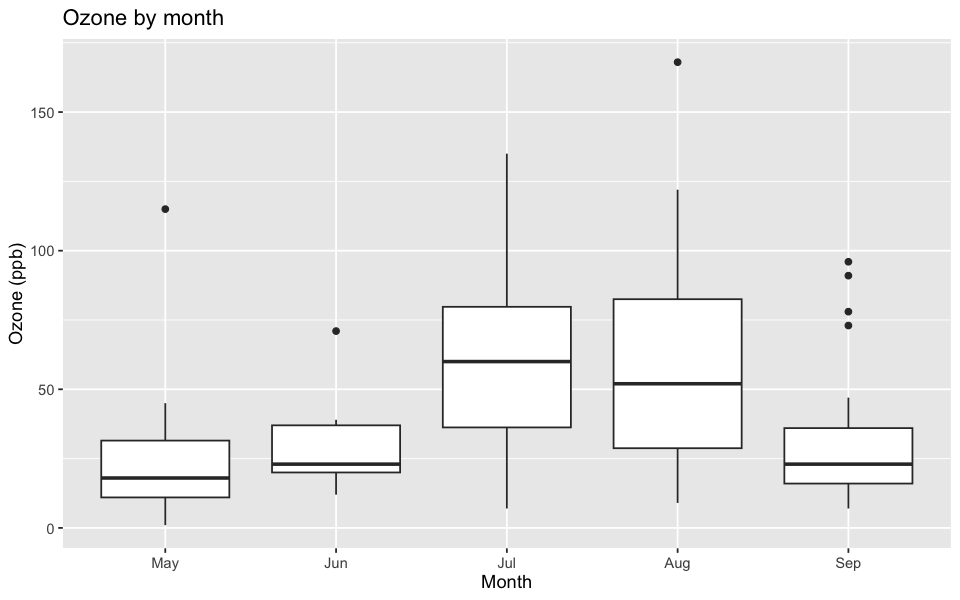

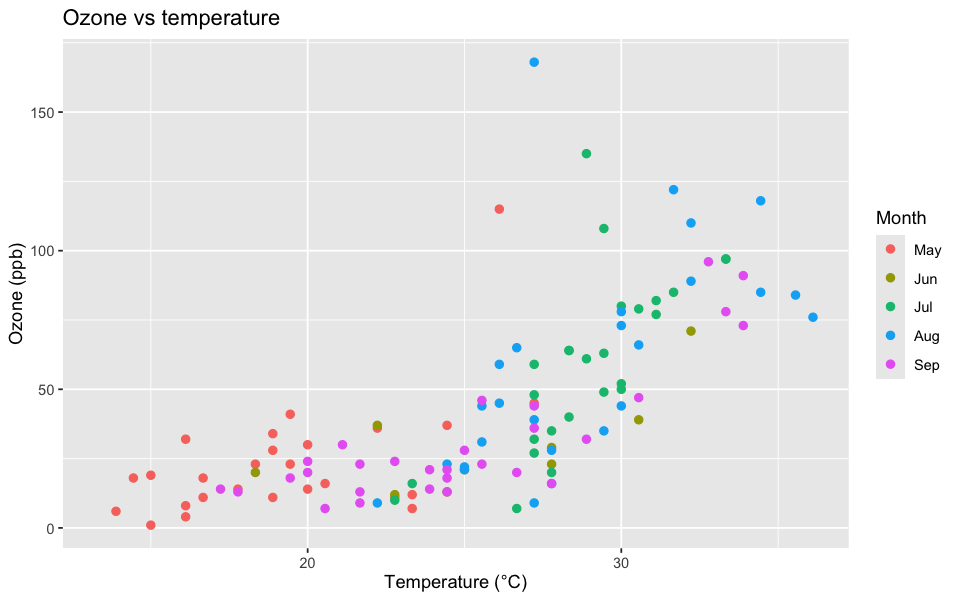

In [6]:
ggplot(aq, aes(x = Ozone)) +
  geom_histogram(bins = 20, fill = "grey70", colour = "white") +
  labs(title = "Daily ozone", x = "Ozone (ppb)", y = "Number of days")

ggplot(aq, aes(x = factor(Month, labels = month.abb[5:9]), y = Ozone)) +
  geom_boxplot() +
  labs(title = "Ozone by month", x = "Month", y = "Ozone (ppb)")

ggplot(aq, aes(x = TempC, y = Ozone, colour = factor(Month, labels = month.abb[5:9]))) +
  geom_point(size = 2) +
  labs(title = "Ozone vs temperature", x = "Temperature (°C)", y = "Ozone (ppb)", colour = "Month")

**Model answer.** The histogram is strongly **right-skewed**: most days are below 50 ppb, a few exceed 100, so a mean alone is a poor summary and a log scale is natural. The boxplots show the seasonal pattern (July–August highest and most variable). The scatter plot shows ozone rising steeply with temperature, and that the months overlap: part of the "month effect" is a temperature effect. None of the plots shows the 37 missing days: ggplot2 drops them with a “Removed 37 rows” warning, which is worth reporting rather than ignoring.

### R5. Repetition without copy-paste (20 min)

Use `sapply()` or `replicate()` to compute the median ozone of 1,000 **bootstrap resamples** (resample the observed ozone values with replacement). Report the 5 % and 95 % quantiles of these medians. What does their spread describe?

In [7]:
oz <- aq$Ozone[!is.na(aq$Ozone)]
set.seed(2026)
meds <- replicate(1000, median(sample(oz, replace = TRUE)))
round(q90(meds), 1)

5%  50%  95% 
24.0 31.5 37.0

**Model answer.** The bootstrap medians range from about 24 to about 37 ppb (5 %–95 %; the exact values depend on the seed). This spread approximates the **sampling uncertainty** of the median: how much it would vary between repeated samples like this one. It says nothing about the variation of individual days, and it again treats days as independent.

## Part 2 — Probability

### P1. Four functions per distribution (30 min)

R names distribution functions `d` (density or probability mass), `p` (cumulative probability), `q` (quantile) and `r` (random draws). For each, write one line and say what it returns:

- (a) the density of Normal(10, 2) at 12;
- (b) P(X ≤ 12) for that normal distribution;
- (c) its 90th percentile;
- (d) 5 random draws from it;
- (e) P(Y = 3) for Binomial(10, 0.3);
- (f) P(Y ≤ 3) for that binomial;
- (g) P(N ≥ 5) for Poisson with mean 2.

In [8]:
c(density_at_12 = dnorm(12, 10, 2), P_le_12 = pnorm(12, 10, 2), q90 = qnorm(.9, 10, 2))
rnorm(5, 10, 2)
c(binom_eq3 = dbinom(3, 10, .3), binom_le3 = pbinom(3, 10, .3), pois_ge5 = 1 - ppois(4, 2))

density_at_12       P_le_12           q90 
    0.1209854     0.8413447    12.5631031

[1]  8.358171  7.570563 10.077762  8.291591 13.231610

binom_eq3  binom_le3   pois_ge5 
0.26682793 0.64961072 0.05265302

**Model answer.** (a) 0.121 — a density (per unit of x), not a probability; (b) 0.841 — a probability; (c) 12.56 — a value of x; (d) five numbers — a random vector that changes with the seed; (e) 0.267 and (f) 0.650 — probabilities from a probability mass function and its CDF; (g) 0.053. Keeping track of *what kind of number* each function returns avoids many later errors.

### P2. Densities are not probabilities (20 min)

X is uniform on [0, 0.25]. (a) What is its density? (b) What are P(X = 0.1) and P(0.05 < X < 0.15)? (c) Why can a density be larger than 1 when no probability can?

In [9]:
c(density = dunif(0.1, 0, 0.25), P_interval = punif(0.15, 0, 0.25) - punif(0.05, 0, 0.25), P_point = 0)

density P_interval    P_point 
       4.0        0.4        0.0

**Model answer.** (a) 4 (per unit of x) on [0, 0.25]. (b) P(X = 0.1) = 0; P(0.05 < X < 0.15) = 4 × 0.1 = 0.4. (c) A probability is an **area** under the density. With a support only 0.25 wide, the density must be 4 for the total area to be 1.

### P3. Expectation and variance (30 min)

(a) For Y ~ Binomial(10, 0.3), compute E[Y] and Var(Y) **from the probability table** as sums, and compare with np and np(1−p). (b) For X ~ Exponential(rate 0.5), compute E[X] = ∫ x f(x) dx with `integrate()` and compare with 1/rate. (c) Check both by simulation with 100,000 draws.

In [10]:
y <- 0:10; py <- dbinom(y, 10, 0.3)
EY <- sum(y * py); VY <- sum((y - EY)^2 * py)
c(E_table = EY, np = 3, Var_table = VY, npq = 2.1)
EX <- integrate(function(x) x * dexp(x, 0.5), 0, Inf)$value
c(E_integral = EX, one_over_rate = 2)
set.seed(2026); c(E_Y_sim = mean(rbinom(1e5, 10, .3)), Var_Y_sim = var(rbinom(1e5, 10, .3)), E_X_sim = mean(rexp(1e5, .5)))

E_table        np Var_table       npq 
      3.0       3.0       2.1       2.1

E_integral one_over_rate 
            2             2

E_Y_sim Var_Y_sim   E_X_sim 
 3.006630  2.097175  2.005212

**Model answer.** E[Y] = 3 and Var(Y) = 2.1 from the table, matching np and np(1−p); E[X] = 2 = 1/rate by numerical integration; simulation agrees to two decimals. Expectations are weighted averages over all possible values — the same idea we will use for posterior means on Day 2.

### P4. Conditional probability and Bayes' rule (40 min)

A fictional screening test detects a condition in **95 %** of people who have it, and gives a false positive in **4 %** of people who do not. **2 %** of the tested population has the condition.

(a) Imagine 10,000 people and fill in a 2×2 table of counts: condition yes/no by test positive/negative. (b) What is P(condition | positive)? (c) The person is tested again, independently given their condition, and is again positive. Update. (d) In one sentence: why is (b) so much lower than 95 %?

In [11]:
prior <- c(yes = 0.02, no = 0.98); lik_pos <- c(yes = 0.95, no = 0.04)
counts <- round(10000 * rbind(positive = prior * lik_pos, negative = prior * (1 - lik_pos)))
counts
post1 <- prior * lik_pos / sum(prior * lik_pos)
post2 <- post1 * lik_pos / sum(post1 * lik_pos)
round(rbind(after_one_positive = post1, after_two_positives = post2), 3)

,yes,no
positive,190,392
negative,10,9408


,yes,no
after_one_positive,0.326,0.674
after_two_positives,0.920,0.080


**Model answer.** (a) Positives: 190 with the condition, 392 without; negatives: 10 and 9,408. (b) P(condition | positive) = 190 / 582 ≈ **0.33**. (c) After a second positive, ≈ **0.92**. (d) The condition is rare, so false positives from the large healthy group outnumber the true positives. This is Bayes' rule: posterior ∝ prior × likelihood, and the **prior (base rate)** matters. The course is built on exactly this update, with parameters instead of a yes/no condition.

### P5. Joint, marginal and conditional (30 min)

Classify each day in `airquality` as **hot** (TempC > 25) or not, and **high ozone** (Ozone > 60 ppb) or not, using days with ozone observed. (a) Make the 2×2 table of proportions (the **joint** distribution). (b) Give the **marginal** P(high ozone) and the **conditional** P(high ozone | hot) and P(high ozone | not hot). (c) Are the two events independent? (d) Does this show that heat *causes* ozone?

In [12]:
d <- aq[!is.na(aq$Ozone), ]
hot <- d$TempC > 25; high <- d$Ozone > 60
joint <- prop.table(table(hot, high)); round(joint, 3)
c(P_high = mean(high), P_high_given_hot = mean(high[hot]), P_high_given_not_hot = mean(high[!hot]))

       high
hot     FALSE  TRUE
  FALSE 0.448 0.000
  TRUE  0.284 0.267

P_high     P_high_given_hot P_high_given_not_hot 
           0.2672414            0.4843750            0.0000000

**Model answer.** Overall about 27 % of days have high ozone, but about 48 % of hot days and **none** of the other days do: the events are strongly **dependent** (independence would make the conditional equal the marginal). This is an association in observational data; temperature, sunshine (Solar.R) and calm wind occur together, so the table alone cannot separate their effects or establish causation.

### P6. Repeated measurements are not independent (20 min)

A person's 10-second time estimates follow Yᵢⱼ = μ + bᵢ + eᵢⱼ, where person i has a personal offset bᵢ ~ Normal(0, τ = 1) and attempt j adds noise eᵢⱼ ~ Normal(0, σ = 0.5). (a) Simulate 5,000 people with two attempts each. Estimate Var(Y) and the correlation between a person's two attempts. Compare with τ² + σ² and τ²/(τ² + σ²). (b) Why does this matter when 10 attempts per person are analysed as if they were 10 independent observations?

In [13]:
set.seed(2026); n <- 5000; tau <- 1; sigma <- 0.5
b <- rnorm(n, 0, tau); y1 <- 10 + b + rnorm(n, 0, sigma); y2 <- 10 + b + rnorm(n, 0, sigma)
round(c(var_sim = var(y1), var_theory = tau^2 + sigma^2, cor_sim = cor(y1, y2), cor_theory = tau^2 / (tau^2 + sigma^2)), 3)

var_sim var_theory    cor_sim cor_theory 
     1.224      1.250      0.798      0.800

**Model answer.** Var(Y) ≈ 1.25 = τ² + σ² and the correlation between two attempts by the same person ≈ 0.8 = τ²/(τ² + σ²). Attempts from one person share bᵢ, so they carry much less information about the population than 10 independent people would: treating them as independent overstates precision. Day 4 handles this with hierarchical models.

## Part 3 — A little calculus

### C1. Normalising a density (20 min)

A density on [0, 1] is proportional to p(1 − p). (a) Find the constant c so that c·p(1 − p) integrates to 1, analytically and with `integrate()`. (b) Compare c·p(1 − p) with `dbeta(p, 2, 2)`. (c) Why is it often enough in Bayesian statistics to know a density only *up to a constant*?

In [14]:
area <- integrate(function(p) p * (1 - p), 0, 1)$value
c(area = area, c = 1 / area, check_at_0.3 = (1 / area) * 0.3 * 0.7, dbeta_at_0.3 = dbeta(0.3, 2, 2))

area            c check_at_0.3 dbeta_at_0.3 
   0.1666667    6.0000000    1.2600000    1.2600000

**Model answer.** ∫₀¹ p(1 − p) dp = 1/2 − 1/3 = 1/6, so c = 6, and 6p(1 − p) is exactly the Beta(2, 2) density. (c) The shape (which values are more plausible) is determined by the unnormalised function; the constant only rescales it. On Day 2 the posterior is written as prior × likelihood "up to a constant", and recognising the shape of a known density (here, Beta) gives the constant for free.

### C2. Why we work with logarithms (20 min)

(a) Simulate 1,000 values from Normal(0, 1) and compute the product of their densities with `prod(dnorm(x))`. What happens? (b) Compute the sum of log densities instead with `sum(dnorm(x, log = TRUE))`. (c) Use log rules to explain why the two contain the same information.

In [15]:
set.seed(2026); x <- rnorm(1000)
c(product = prod(dnorm(x)), sum_of_logs = sum(dnorm(x, log = TRUE)))

product sum_of_logs 
      0.000   -1408.721

**Model answer.** The product **underflows** to exactly 0 because it is smaller than the tiniest number the computer can store (it is about e⁻¹⁴⁰⁹). The sum of logs, about −1,409, is perfectly representable. Since log(ab) = log a + log b, the log of a product of densities is the sum of their logs: same information, numerically safe. Stan works with log densities for this reason (`target +=`, `normal_lpdf`).

### C3. Finding a maximum (20 min)

f(p) = p⁷(1 − p)³ for p in (0, 1). (a) Find the maximising p analytically: take logs, differentiate, set to zero. (b) Check with `optimize()` and by plotting f. (c) What would change if the exponents were 70 and 30?

[1] 0.7000058

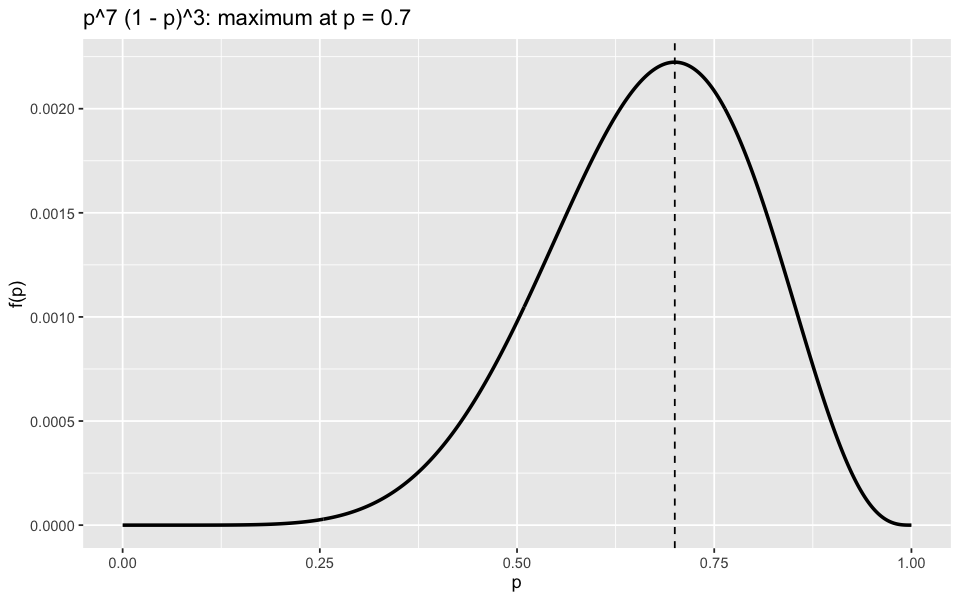

In [16]:
optimize(function(p) 7 * log(p) + 3 * log(1 - p), c(0, 1), maximum = TRUE)$maximum
ggplot(data.frame(p = seq(0, 1, length.out = 500)), aes(x = p, y = p^7 * (1 - p)^3)) +
  geom_line(linewidth = 1) +
  geom_vline(xintercept = 0.7, linetype = 2) +
  labs(title = "p^7 (1 - p)^3: maximum at p = 0.7", x = "p", y = "f(p)")

**Model answer.** log f = 7 log p + 3 log(1 − p); derivative 7/p − 3/(1 − p) = 0 gives p = 0.7, confirmed numerically. With exponents 70 and 30 the maximum is still at 0.7, but the curve is much **narrower**: more data, less uncertainty. You have just found the maximum-likelihood estimate for 7 successes in 10 trials — the starting point of Day 2.

## Part 4 — Simulation

### S1. A probability as a simulated proportion (25 min)

For X ~ Normal(10, 2), estimate P(8 < X < 12) by simulation with 100, 1,000 and 100,000 draws, each with its **Monte Carlo standard error** √(p̂(1 − p̂)/S). Compare with `pnorm`. How does the error shrink as S grows?

In [17]:
exact <- pnorm(12, 10, 2) - pnorm(8, 10, 2)
set.seed(2026)
t(sapply(c(100, 1000, 1e5), function(S) { x <- rnorm(S, 10, 2); p <- mean(x > 8 & x < 12); c(S = S, estimate = p, mcse = sqrt(p * (1 - p) / S)) }))
exact

S,estimate,mcse
1e+02,0.68000,0.046647615
1e+03,0.68900,0.014638272
1e+05,0.68118,0.001473682


[1] 0.6826895

**Model answer.** The exact probability is 0.683. Estimates are within about two MCSEs of it; the MCSE falls from about 0.05 (S = 100) to about 0.0015 (S = 100,000) — it shrinks like 1/√S, so 100× more draws give 10× more precision. All Bayesian computation in this course (Monte Carlo, MCMC, Stan) produces estimates with this kind of numerical error.

### S2. Individual values versus averages (30 min)

Draw 2,000 samples of size n = 10 and of size n = 100 from Normal(10, 2) and keep each sample mean. Compare the SD of the means with 2/√n, and plot both distributions on the same axis. Distinguish (i) the SD of individual observations, (ii) the SD of a sample mean, and (iii) the Monte Carlo error of your estimate of (ii).

n,sd_of_means,theory
<chr>,<dbl>,<dbl>
n = 10,0.6373417,0.6324555
n = 100,0.2054058,0.2000000


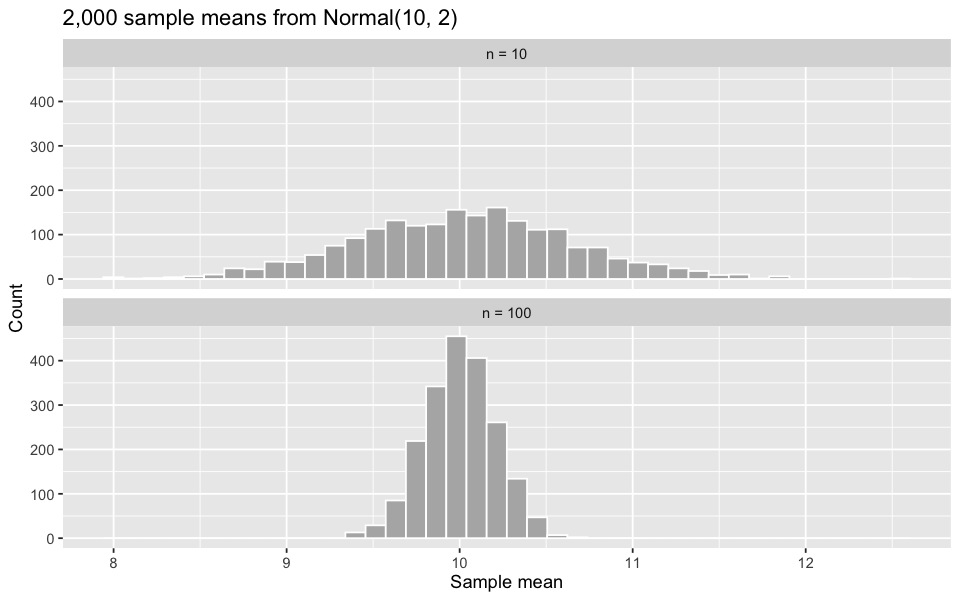

In [18]:
set.seed(2026)
m10 <- replicate(2000, mean(rnorm(10, 10, 2))); m100 <- replicate(2000, mean(rnorm(100, 10, 2)))
means <- tibble(n = rep(c("n = 10", "n = 100"), each = 2000), mean = c(m10, m100))

means |>
  group_by(n) |>
  summarise(sd_of_means = sd(mean)) |>
  mutate(theory = 2 / sqrt(c(10, 100)))

ggplot(means, aes(x = mean)) +
  geom_histogram(bins = 40, fill = "grey70", colour = "white") +
  facet_wrap(~ n, ncol = 1) +
  labs(title = "2,000 sample means from Normal(10, 2)", x = "Sample mean", y = "Count")

**Model answer.** SDs of the means ≈ 0.63 (n = 10) and ≈ 0.20 (n = 100), matching 2/√n. (i) Individual observations have SD 2 whatever n is; (ii) a mean of n independent observations has SD 2/√n; (iii) our estimate of (ii) from 2,000 simulated means is itself slightly uncertain, and more simulations would reduce that — not the quantities (i) or (ii).

### S3. A first likelihood (35 min)

In 10 independent trials there were **7 successes**. (a) On a grid of 1,000 values of p in (0, 1), compute the binomial likelihood `dbinom(7, 10, p)` and plot it against p. (b) Divide the likelihood by its sum over the grid, so the weights sum to 1, and compute the weighted mean of p and the probability that p > 0.5. (c) This is a Bayesian posterior under a flat prior. Which question does it answer that the maximum-likelihood estimate 0.7 alone does not?

grid_mean      P_p_gt_0.5 exact_beta_mean         exact_P 
      0.6666667       0.8867192       0.6666667       0.8867188

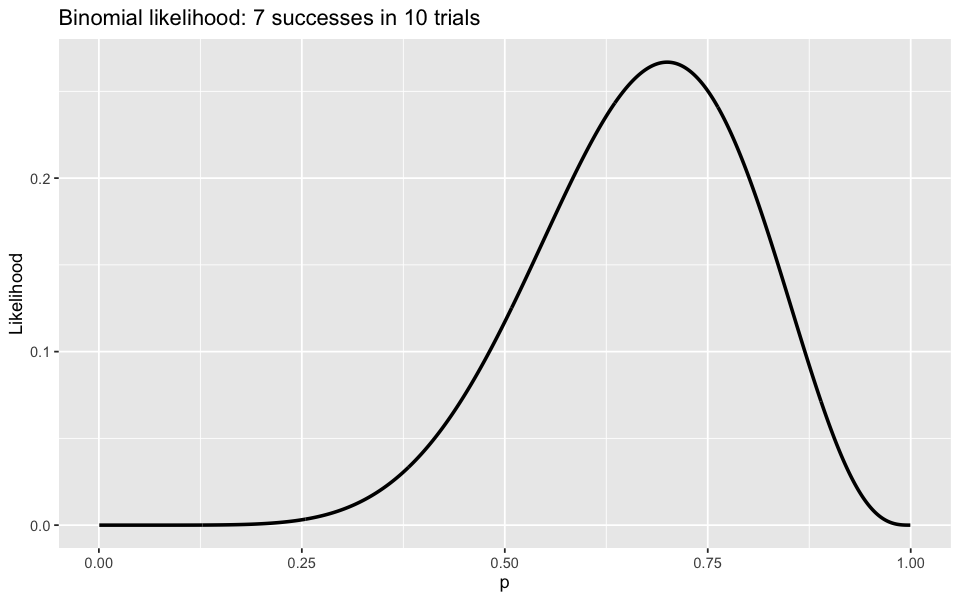

In [19]:
p <- seq(0.0005, 0.9995, length.out = 1000)
lik <- dbinom(7, 10, p); w <- lik / sum(lik)
c(grid_mean = sum(p * w), P_p_gt_0.5 = sum(w[p > 0.5]), exact_beta_mean = 8 / 12, exact_P = 1 - pbeta(.5, 8, 4))
ggplot(data.frame(p, lik), aes(x = p, y = lik)) +
  geom_line(linewidth = 1) +
  labs(title = "Binomial likelihood: 7 successes in 10 trials", x = "p", y = "Likelihood")

**Model answer.** The likelihood peaks at 0.7 and is broad. Normalised over the grid (flat prior), the mean of p is ≈ 0.667 and P(p > 0.5) ≈ 0.89; these equal the exact Beta(8, 4) results. A posterior answers questions **about the parameter with uncertainty** ("how probable is p > 0.5?") rather than giving only a best guess. Day 2 starts exactly here.

## Part 5 — Your own research question

The final assignment is an exercise collection on a supplied dataset, but the aim of the course is that you can use Bayesian methods and Stan in your own research. Thinking about your own data now makes the course more useful. In 150–300 words, describe:

1. A question from your research that involves uncertainty: an estimate, a comparison, or a prediction.
2. The **outcome** you would measure, its type (count, yes/no, continuous, positive) and units.
3. The **observational unit**, and whether observations come in groups or repeated measurements (people, sites, batches, time points).
4. Something that is **already known** about the answer (a published result, an earlier analysis, expert knowledge) that could inform a prior or serve as a check.
5. One thing you are unsure how to model.

There is no right answer, and nothing is submitted. Keep your notes: they are useful when we discuss applying the methods to your own research on Day 6.

**My research question:** *(write here)*

> **Instructor note.** No model answer. Look for a concrete outcome with units, a stated observational unit and grouping structure, and some prior knowledge or known result; these are the ingredients of a Bayesian analysis of the student's own data.

## Part 6 — Self-check

Tick what you can do comfortably. For anything you cannot, write a short note to bring to Day 1. Nobody is expected to tick everything.

- [ ] Run a notebook from a fresh kernel with the **R (bayes)** kernel, and compile the Stan check model.
- [ ] Read, subset and summarise a data frame, handling missing values deliberately.
- [ ] Write a small function and use `sapply()` / `replicate()`.
- [ ] Make labelled plots that answer a question.
- [ ] Use the `d`/`p`/`q`/`r` functions and say what each returns.
- [ ] Explain why a density can exceed 1.
- [ ] Compute an expectation as a weighted sum or an integral.
- [ ] Apply Bayes' rule with a base rate.
- [ ] Distinguish joint, marginal and conditional probabilities.
- [ ] Explain why repeated measurements on the same unit are correlated.
- [ ] Explain why we add log densities instead of multiplying densities.
- [ ] Estimate a probability by simulation and give its Monte Carlo error.
- [ ] Explain the difference between a likelihood and a posterior.

**Bring to Day 1:** the two or three questions you most want answered.

**My questions for Day 1:** *(write here)*